### **Setup initialization**

In [3]:
# %pip install mdatagen
# %pip install --upgrade scipy
# %pip install display
# %pip install MissForest
# %pip install lightgbm
# %pip install openpyxl
# %pip install missingpy
# %pip install impyute
# %pip install MIDASpy
# %pip uninstall tensorflow tensorflow-cpu tensorflow-gpu -y
# %pip install tensorflow==2.16.1
# %pip install ipykernel
# conda install -n chip_env ipykernel --update-deps --force-reinstall

In [1]:
# SETTING UP AN ENVIRONMENT FOR THE MIDASpy PACKAGE
# conda install pip
# %pip install MIDASpy
# %pip install MissForest
# %pip install lightgbm
# %pip install tqdm
# %pip install seaborn
# %pip install impyute
# %pip install miceforest

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.7/42.7 MB 42.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [miceforest]2 [miceforest]
Note: you may need to restart the kernel to use updated packages.


In [1]:
 %load_ext autoreload
 %autoreload 2

In [2]:
# FOR MIDASpy package
import my_imp_methods_midas
import tensorflow as tf
import pandas as pd
from IPython.display import display
import numpy as np
import data_preprocessing
import functions_to_handle_data_Eleanor
from sklearn.ensemble import RandomForestClassifier

/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:2: FutureWarning: In the future `np.bool` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, 'bool'):
2025-08-11 10:06:28.218178: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F AVX512_VNNI FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-08-11 10:06:29.305322: I tensorflow/core/util/port.cc:104] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-08-11 10:06:29.657852: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11

In [2]:
# FOR DATAWIG!
import my_imp_methods_datawig
import pandas as pd
from IPython.display import display
import numpy as np
import data_preprocessing
import functions_to_handle_data_Eleanor
from sklearn.ensemble import RandomForestClassifier

In [22]:
data = pd.read_csv('/home/ch268692/pjia_proj/data/data_eleanor_5Aug2025.csv', 
                 low_memory=False, index_col='id')
# data_old = pd.read_csv('//rc-fs.tch.harvard.edu/carra-dw/Groups/PCORI_MachineLearning/Preprocessed_data/data_complete.csv', 
#                  low_memory=False, index_col='id')


In [23]:
len(data)

11889

In [24]:
# Checking unique values in each column
for col in data.columns:
    print(f"Unique values in column '{col}': {data[col].unique()}")
    # print(f"Number of unique values for the {col} column: {data[col].nunique()}")
# print("Number of columns in the data: ", len(data.columns))
# print("Number of columns in the data: ", len(data_old.columns))

Unique values in column 'male': [0 1]
Unique values in column 'age': [12  7  6 10  3  5  8  4 11 16 18 15 14  9 13 17  2 20  1 19 21 22  0]
Unique values in column 'jia_cat': ['Polyarthritis  (Rheumatoid factor negative)'
 'Undifferentiated arthritis' 'Oligoarthritis'
 'Enthesitis related arthritis' 'Systemic arthritis'
 'Polyarthritis  (Rheumatoid factor positive)' 'Psoriatic arthritis' nan]
Unique values in column 'insurance': ['private' 'public' 'other' 'uninsured' nan]
Unique values in column 'income_cat': [nan  6.  1.  2.  5.  4.  3.]
Unique values in column 'educate_cat': [ 3. nan  4.  5.  2.  1.]
Unique values in column 'race_amerind': [0 1]
Unique values in column 'race_asian': [0 1]
Unique values in column 'race_black': [0 1]
Unique values in column 'race_mideast': [0 1]
Unique values in column 'race_nathwn': [0 1]
Unique values in column 'race_white': [0 1]
Unique values in column 'hispanic': [0 1]
Unique values in column 'hlab27': ['Negative' nan 'Positive']
Unique values in



In [12]:
# Histogram of distribution of the data

import pandas as pd
import matplotlib.pyplot as plt
import math

plot_cols = [col for col in data.columns if 'score' in col.lower() or 'jadas' in col.lower() or 'physcore' in col.lower() or 'rheurate' in col.lower() or 'actjonum' in col.lower()]

n_cols = 3 
n_plots = len(plot_cols)
n_rows = math.ceil(n_plots / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 8 * n_rows))
axes = axes.flatten() 

for ax, col in zip(axes, plot_cols):
    if pd.api.types.is_numeric_dtype(data[col]):
        data[col].hist(bins=30, ax=ax, edgecolor='black')
        ax.set_title(f'Histogram of {col}')
        ax.set_xlabel(col)
        ax.set_ylabel('Frequency')
    else:
        data[col].value_counts().plot(kind='bar', ax=ax, edgecolor='black')
        ax.set_title(f'Bar plot of {col}')
        ax.set_xlabel(col)
        ax.set_ylabel('Count')
    ax.grid(False)

# Turn off any unused subplots
for i in range(len(plot_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.savefig(f'grid_hist.png')
# plt.show()

### **Data structuring**

In [9]:
_basepath = '/home/ch268692/pjia_proj/models_full_dataset'
_filepath = '/home/ch268692/pjia_proj/data'
_filename = 'data_eleanor_5Aug2025.csv'
_filename_mapped = 'data_mapped_cols_not_enc.csv'
data_hyperparam = {'basepath': _basepath, 'filepath': _filepath, 'filename': _filename, 'filename_mapped': _filename_mapped, 
                   'med_boolean':True, 'encoding_flag': False}
# structured_data = functions_to_handle_data_Eleanor.data_loader_dynamics(data_hyperparam)
# structured_data = data_preprocessing.choosing_columns(data_hyperparam)
organized_data = functions_to_handle_data_Eleanor.create_kfold_splits(data_hyperparam, n_splits=5, output_dir="../fold_subject_ids")


Successfully loaded the pre-processed datafile!
Loaded subject IDs for fold 0 from files.
Loaded subject IDs for fold 1 from files.
Loaded subject IDs for fold 2 from files.
Loaded subject IDs for fold 3 from files.
Loaded subject IDs for fold 4 from files.


In [10]:
# Encoded categorical data
_filename_mapped_enc = 'data_mapped_cols_enc.csv'
data_hyperparam_enc = {'basepath': _basepath, 'filepath': _filepath, 'filename': _filename, 'filename_mapped': _filename_mapped_enc, 
                   'med_boolean':True, 'encoding_flag': True}
# structured_data_enc = functions_to_handle_data_Eleanor.data_loader_dynamics(data_hyperparam_enc)
organized_data_enc = functions_to_handle_data_Eleanor.create_kfold_splits(data_hyperparam_enc, n_splits=5, output_dir="../fold_subject_ids")

Successfully loaded the pre-processed datafile!
Loaded subject IDs for fold 0 from files.
Loaded subject IDs for fold 1 from files.
Loaded subject IDs for fold 2 from files.
Loaded subject IDs for fold 3 from files.
Loaded subject IDs for fold 4 from files.


In [5]:
import os.path as osp
_FILEPATH = '/home/ch268692/pjia_proj/data/'

df_enc = pd.read_csv(osp.join(_FILEPATH, "models_limited_dataset/data_mapped_cols_enc.csv")) 
df_not_enc = pd.read_csv(osp.join(_FILEPATH, "models_limited_dataset/data_mapped_cols_not_enc.csv"))

pct_missing_enc = df_enc.isnull().mean() * 100
pct_missing_not_enc = df_not_enc.isnull().mean() * 100

print("Percentage missing (encoded):")
print(pct_missing_enc.sort_values(ascending=False))

print("\nPercentage missing (not encoded):")
print(pct_missing_not_enc.sort_values(ascending=False))

# Optional: save results
pct_missing_enc.to_csv("percentage_missing_encoded.csv", header=["pct_missing"])
pct_missing_not_enc.to_csv("percentage_missing_not_encoded.csv", header=["pct_missing"])

Percentage missing (encoded):
sacroiliac_tenderness_month.6    99.768733
sacroiliac_tenderness_month.0    95.143386
UPEXTR_T_SCORE.36m               88.482886
UPEXTR_T_SCORE.30m               85.060130
PAIN_T_SCORE.36m                 84.967623
                                   ...    
methotrexate_month.31             0.000000
methotrexate_month.30             0.000000
methotrexate_month.29             0.000000
methotrexate_month.28             0.000000
otherBiologics_month.2            0.000000
Length: 386, dtype: float64

Percentage missing (not encoded):
sacroiliac_tenderness_month.6    99.768733
sacroiliac_tenderness_month.0    95.143386
UPEXTR_T_SCORE.36m               88.482886
UPEXTR_T_SCORE.30m               85.060130
PAIN_T_SCORE.36m                 84.967623
                                   ...    
methotrexate_month.31             0.000000
methotrexate_month.30             0.000000
methotrexate_month.29             0.000000
methotrexate_month.28             0.000000
othe

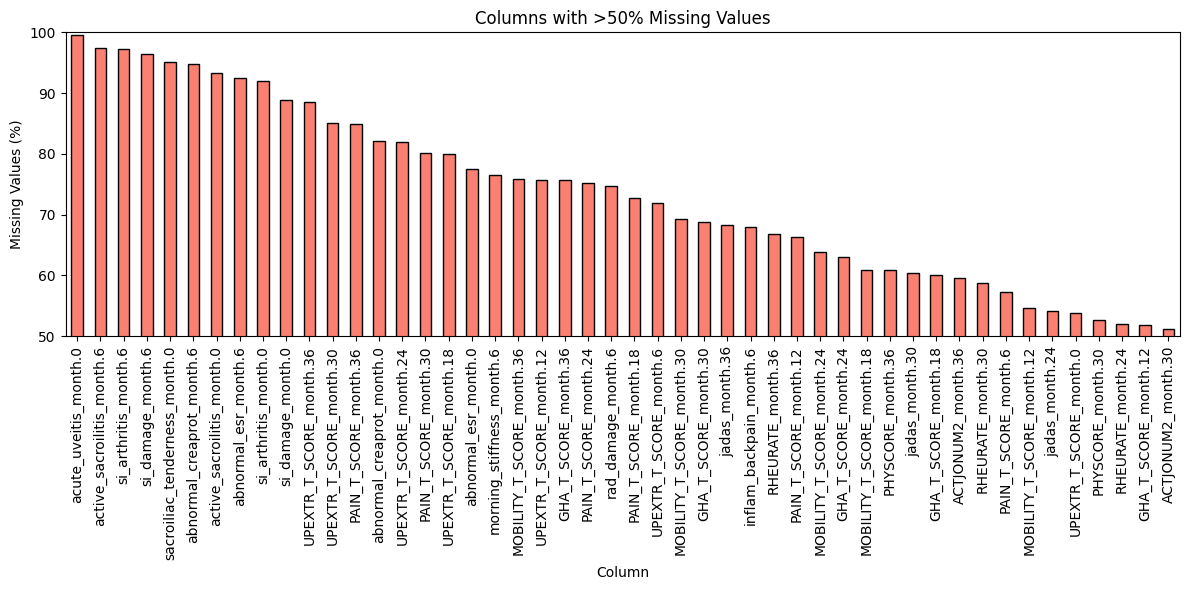

In [20]:
# Histogram of the missigness of the data

import pandas as pd
import matplotlib.pyplot as plt
import os.path as osp

_FILEPATH = '/home/ch268692/pjia_proj/'
df_enc = pd.read_csv(osp.join(_FILEPATH, "models_full_dataset/data_mapped_cols_enc.csv")) 

missing_percentage = df_enc.isnull().mean() * 100
missing_percentage = missing_percentage[missing_percentage > 50].sort_values(ascending=False)

if not missing_percentage.empty:
    plt.figure(figsize=(12, 6))
    missing_percentage.plot(kind='bar', edgecolor='black', color='salmon')
    plt.title('Columns with >50% Missing Values')
    plt.xlabel('Column')
    plt.ylabel('Missing Values (%)')
    plt.ylim(50, 100)
    plt.tight_layout()
    plt.show()
else:
    print("No columns with more than 50% missing values.")

### **Data preprocessing**

In [20]:
# organized_data[0]['train']['type_1'][0]['sacroiliac_tenderness_month.6']

### **Choosing the subset of the data**

In [9]:
print(len(organized_data))
print(len(organized_data[0]['train']['type_1']))
print(len(organized_data[0]['train']['type_2']))
print(organized_data[0]['train']['type_1'][0].shape)
print(organized_data[0]['train']['type_2'][0].shape)
print(organized_data[0]['train']['type_2'][1].shape)
print(organized_data[0]['train']['type_3'][0].shape)
print(organized_data[0]['train']['type_4'][0].shape)


5
1
7
(1729, 100)
(1729, 41)
(1729, 83)
(1729, 98)
(1729, 98)


In [10]:
print(organized_data[0]['train']['type_2'][0].shape)
print(organized_data[0]['train']['type_2'][1].shape)
# print(organized_data[0]['train']['type_2'][2].shape)

(1729, 41)
(1729, 83)


In [11]:
# pd.set_option('display.max_rows', None)
# pd.set_option('display.max_columns', None)
organized_data[0]['train']['type_1'][0].columns.to_series().to_csv('all_columns.csv', index=False)
print(organized_data[0]['train']['type_1'][0].columns)
print(organized_data[0]['train']['type_2'][0].columns)
print(organized_data[0]['train']['type_2'][1].columns)

# Optionally reset to default after
# pd.reset_option('display.max_rows')
# pd.reset_option('display.max_columns')

Index(['id', 'totjoint_month.0', 'rad_damage_month.0', 'uveitis_new_month.0',
       'active_sacroilitis_month.0', 'active_enthesitis_month.0',
       'psoriasis_month.0', 'newmed_month.0', 'steroid_month.0',
       'PHYSCORE_month.0', 'RHEURATE_month.0', 'ACTJONUM2_month.0',
       'jadas_month.0', 'GHA_T_SCORE_month.0', 'DIS_ACT_month.0',
       'RHEUM_PAIN_month.0', 'totjoint_month.6', 'rad_damage_month.6',
       'uveitis_new_month.6', 'active_sacroilitis_month.6',
       'active_enthesitis_month.6', 'psoriasis_month.6', 'newmed_month.6',
       'steroid_month.6', 'PHYSCORE_month.6', 'RHEURATE_month.6',
       'ACTJONUM2_month.6', 'jadas_month.6', 'GHA_T_SCORE_month.6',
       'DIS_ACT_month.6', 'RHEUM_PAIN_month.6', 'id', 'antiIL1_month.1',
       'antiIL6_month.1', 'methotrexate_month.1', 'otherBiologics_month.1',
       'otherDMARDs_month.1', 'smallMoleculeInhibitors_month.1',
       'TNFi_month.1', 'antiIL1_month.2', 'antiIL6_month.2',
       'methotrexate_month.2', 'otherBiolo

In [24]:
organized_data[0]['train'].keys()

dict_keys(['type_1', 'type_2', 'type_3', 'type_4'])

In [18]:
for i, j in organized_data[0]['train'].items():
    print(i)
    for k in range(len(j)):
        print('k is ', k)
        print('Train: ', j[k].shape)
        
for i, j in organized_data[0]['test'].items():
    print()
    for k in range(len(j)):
        print('k is ', k)
        print('Test: ', j[k].shape)

type_1
k is  0
Train:  (1729, 100)
type_2
k is  0
Train:  (1729, 41)
k is  1
Train:  (1729, 83)
k is  2
Train:  (1729, 26)
k is  3
Train:  (1729, 26)
k is  4
Train:  (1729, 26)
k is  5
Train:  (1729, 26)
k is  6
Train:  (1729, 26)
type_3
k is  0
Train:  (1729, 98)
k is  1
Train:  (1729, 83)
k is  2
Train:  (1729, 26)
k is  3
Train:  (1729, 26)
k is  4
Train:  (1729, 26)
k is  5
Train:  (1729, 26)
type_4
k is  0
Train:  (1729, 98)
k is  1
Train:  (1729, 83)
k is  2
Train:  (1729, 26)
k is  3
Train:  (1729, 26)
k is  4
Train:  (1729, 26)

k is  0
Test:  (433, 100)

k is  0
Test:  (433, 41)
k is  1
Test:  (433, 83)
k is  2
Test:  (433, 26)
k is  3
Test:  (433, 26)
k is  4
Test:  (433, 26)
k is  5
Test:  (433, 26)
k is  6
Test:  (433, 26)

k is  0
Test:  (433, 98)
k is  1
Test:  (433, 83)
k is  2
Test:  (433, 26)
k is  3
Test:  (433, 26)
k is  4
Test:  (433, 26)
k is  5
Test:  (433, 26)

k is  0
Test:  (433, 98)
k is  1
Test:  (433, 83)
k is  2
Test:  (433, 26)
k is  3
Test:  (433, 26)
k i

In [11]:
def extract_types(organized_data):
    organized_data_subset = []
    for fold_dict in organized_data:
        # Each fold_dict: {"train_i": train_dict, "test_i": test_dict}
        new_fold_dict = {}
        for set_name, set_dict in fold_dict.items():  # set_name: "train_1", etc. set_dict: {type_1:..., type_2:..., type_3:..., type_4:...}
            new_set_dict = {}
            # type_2: take only first (index 0) and second (index 1) elements, if available
            if "type_2" in set_dict:
                new_set_dict["type_2"] = set_dict["type_2"][:2]
            # type_3: take only first (index 0) element (corresponds to (0,6)), if available
            if "type_3" in set_dict:
                new_set_dict["type_3"] = set_dict["type_3"][:1]
            new_fold_dict[set_name] = new_set_dict
        organized_data_subset.append(new_fold_dict)
    return organized_data_subset

In [12]:
organized_data_subset = extract_types(organized_data)
organized_data_enc_subset = extract_types(organized_data_enc)

print(len(organized_data_subset))
print(organized_data_subset[0]['train']['type_2'][0].shape)
print(organized_data_subset[0]['train']['type_2'][1].shape)
print(organized_data_subset[0]['train']['type_3'][0].shape)
print(organized_data_subset[0]['test']['type_3'][0].shape)


5
(1729, 41)
(1729, 83)
(1729, 98)
(433, 98)


In [8]:
print(organized_data_subset[0]['train']['type_2'][0].columns)

Index(['totjoint_month.0', 'rad_damage_month.0', 'uveitis_new_month.0',
       'active_sacroilitis_month.0', 'active_enthesitis_month.0',
       'psoriasis_month.0', 'newmed_month.0', 'steroid_month.0',
       'PHYSCORE_month.0', 'RHEURATE_month.0', 'ACTJONUM2_month.0',
       'jadas_month.0', 'GHA_T_SCORE_month.0', 'DIS_ACT_month.0',
       'RHEUM_PAIN_month.0', 'id', 'male', 'age', 'jia_cat', 'insurance',
       'income_cat', 'educate_cat', 'race_amerind', 'race_asian', 'race_black',
       'race_mideast', 'race_nathwn', 'race_white', 'hispanic', 'hlab27',
       'anticcp', 'diff_dx_symp_mth', 'trisomy21', 'famhx_rheum', 'famhx_ibd',
       'famhx_uveitis', 'famhx_other_aid', 'ibd', 'asthma', 'other_aid',
       'iei'],
      dtype='object')


In [7]:
print(organized_data_subset[0]['train']['type_2'][1].columns)

Index(['totjoint_month.6', 'rad_damage_month.6', 'uveitis_new_month.6',
       'active_sacroilitis_month.6', 'active_enthesitis_month.6',
       'psoriasis_month.6', 'newmed_month.6', 'steroid_month.6',
       'PHYSCORE_month.6', 'RHEURATE_month.6', 'ACTJONUM2_month.6',
       'jadas_month.6', 'GHA_T_SCORE_month.6', 'DIS_ACT_month.6',
       'RHEUM_PAIN_month.6', 'antiIL1_month.1', 'antiIL6_month.1',
       'methotrexate_month.1', 'otherBiologics_month.1', 'otherDMARDs_month.1',
       'smallMoleculeInhibitors_month.1', 'TNFi_month.1', 'antiIL1_month.2',
       'antiIL6_month.2', 'methotrexate_month.2', 'otherBiologics_month.2',
       'otherDMARDs_month.2', 'smallMoleculeInhibitors_month.2',
       'TNFi_month.2', 'antiIL1_month.3', 'antiIL6_month.3',
       'methotrexate_month.3', 'otherBiologics_month.3', 'otherDMARDs_month.3',
       'smallMoleculeInhibitors_month.3', 'TNFi_month.3', 'antiIL1_month.4',
       'antiIL6_month.4', 'methotrexate_month.4', 'otherBiologics_month.4',
    

In [9]:
print(organized_data_subset[0]['train']['type_3'][0].columns)

Index(['totjoint_month.0', 'rad_damage_month.0', 'uveitis_new_month.0',
       'active_sacroilitis_month.0', 'active_enthesitis_month.0',
       'psoriasis_month.0', 'newmed_month.0', 'steroid_month.0',
       'PHYSCORE_month.0', 'RHEURATE_month.0', 'ACTJONUM2_month.0',
       'jadas_month.0', 'GHA_T_SCORE_month.0', 'DIS_ACT_month.0',
       'RHEUM_PAIN_month.0', 'totjoint_month.6', 'rad_damage_month.6',
       'uveitis_new_month.6', 'active_sacroilitis_month.6',
       'active_enthesitis_month.6', 'psoriasis_month.6', 'newmed_month.6',
       'steroid_month.6', 'PHYSCORE_month.6', 'RHEURATE_month.6',
       'ACTJONUM2_month.6', 'jadas_month.6', 'GHA_T_SCORE_month.6',
       'DIS_ACT_month.6', 'RHEUM_PAIN_month.6', 'antiIL1_month.1',
       'antiIL6_month.1', 'methotrexate_month.1', 'otherBiologics_month.1',
       'otherDMARDs_month.1', 'smallMoleculeInhibitors_month.1',
       'TNFi_month.1', 'antiIL1_month.2', 'antiIL6_month.2',
       'methotrexate_month.2', 'otherBiologics_month.2

In [20]:
for col in organized_data_subset[0]['train']['type_2'][0].columns:
    values = organized_data_subset[0]['train']['type_2'][0][col].unique()
    print(f"Column '{col}' contains unique values: {values}")

Column 'totjoint_month.0' contains unique values: ['>= 5 joints' '< 5 joints' nan]
Column 'rad_damage_month.0' contains unique values: ['No' nan 'Yes']
Column 'uveitis_new_month.0' contains unique values: ['No' nan 'Yes']
Column 'active_sacroilitis_month.0' contains unique values: [nan 'Yes']
Column 'active_enthesitis_month.0' contains unique values: ['No' 'Yes' nan]
Column 'psoriasis_month.0' contains unique values: ['No' 'Yes' nan]
Column 'newmed_month.0' contains unique values: ['Yes' 'No' nan]
Column 'steroid_month.0' contains unique values: [0.]
Column 'PHYSCORE_month.0' contains unique values: [ 9.   2.   3.   0.   8.   4.   5.   7.   6.   3.5  1.   0.5 10.   4.5
  nan  2.5  7.5  5.9  1.5  5.5  8.5  6.5  9.5]
Column 'RHEURATE_month.0' contains unique values: [nan  4.  5.  3.  0.  2.  6.  1.  8.  7.  9. 10.]
Column 'ACTJONUM2_month.0' contains unique values: [10.  2.  5.  0.  6.  7.  3.  1.  4.  9.  8. nan]
Column 'jadas_month.0' contains unique values: [ nan 14.  13.   9.  19.   

In [8]:
for col in organized_data_subset[0]['train']['type_2'][0].columns:
    types = set(type(x) for x in organized_data_subset[0]['train']['type_2'][0][col] if pd.notnull(x))
    print(f"Column '{col}' contains types: {types}")

Column 'totjoint_month.0' contains types: {<class 'str'>}
Column 'rad_damage_month.0' contains types: {<class 'str'>}
Column 'uveitis_new_month.0' contains types: {<class 'str'>}
Column 'active_sacroilitis_month.0' contains types: {<class 'str'>}
Column 'active_enthesitis_month.0' contains types: {<class 'str'>}
Column 'psoriasis_month.0' contains types: {<class 'str'>}
Column 'newmed_month.0' contains types: {<class 'str'>}
Column 'steroid_month.0' contains types: {<class 'float'>}
Column 'PHYSCORE_month.0' contains types: {<class 'float'>}
Column 'RHEURATE_month.0' contains types: {<class 'float'>}
Column 'ACTJONUM2_month.0' contains types: {<class 'float'>}
Column 'jadas_month.0' contains types: {<class 'float'>}
Column 'GHA_T_SCORE_month.0' contains types: {<class 'float'>}
Column 'DIS_ACT_month.0' contains types: {<class 'float'>}
Column 'RHEUM_PAIN_month.0' contains types: {<class 'float'>}
Column 'id' contains types: {<class 'int'>}
Column 'male' contains types: {<class 'int'>}


In [16]:
organized_data_subset[0]['train']['type_2'][1].dtypes[30:]

antiIL1_month.2                      int64
antiIL6_month.2                      int64
methotrexate_month.2                 int64
otherBiologics_month.2               int64
otherDMARDs_month.2                  int64
smallMoleculeInhibitors_month.2      int64
TNFi_month.2                         int64
antiIL1_month.3                      int64
antiIL6_month.3                      int64
methotrexate_month.3                 int64
otherBiologics_month.3               int64
otherDMARDs_month.3                  int64
smallMoleculeInhibitors_month.3      int64
TNFi_month.3                         int64
antiIL1_month.4                      int64
antiIL6_month.4                      int64
methotrexate_month.4                 int64
otherBiologics_month.4               int64
otherDMARDs_month.4                  int64
smallMoleculeInhibitors_month.4      int64
TNFi_month.4                         int64
antiIL1_month.5                      int64
antiIL6_month.5                      int64
methotrexat

### **Checking on the missingness**

In [27]:
def print_low_nonmissing_across_folds(organized_data, threshold=100):
    """
    organized_data: list of fold_dicts
    threshold: int
    """
    for fold_idx, fold in enumerate(organized_data):
        for set_name in ['train', 'test']:
            for type_key in ['type_2', 'type_3']:
                # Can be list of DataFrames (for type_2, usually two; for type_3, usually one)
                df_list = fold[set_name][type_key]
                for i, df in enumerate(df_list):
                    non_missing_counts = df.notnull().sum()
                    low_count_cols = non_missing_counts[non_missing_counts < threshold]
                    if not low_count_cols.empty:
                        print(f"\nFOLD {fold_idx+1} | {set_name.upper()} | {type_key} dataset {i+1}:")
                        print(low_count_cols)

In [28]:
print_low_nonmissing_across_folds(organized_data_subset, threshold=10)
# or for encoded:
print_low_nonmissing_across_folds(organized_data_enc_subset, threshold=10)


FOLD 4 | TEST | type_2 dataset 2:
active_sacroilitis_month.6    8
dtype: int64

FOLD 4 | TEST | type_3 dataset 1:
active_sacroilitis_month.6    8
dtype: int64

FOLD 4 | TEST | type_2 dataset 2:
active_sacroilitis_month.6    8
dtype: int64

FOLD 4 | TEST | type_3 dataset 1:
active_sacroilitis_month.6    8
dtype: int64


### **Imputation methods**

In [13]:
output_dir_imp = '/home/ch268692/pjia_proj/models_full_dataset/imp_data'

In [32]:
# Dictionary of all the methods
imputation_methods = {
    # 'miss_forest_dflt': my_imp_methods_midas.my_missforest_dflt,
    # 'miss_forest_cstm': my_imp_methods_midas.my_missforest_cstm,
    # 'my_iterative_imputer': my_imp_methods_midas.my_iterative_imputer,
    # 'em_method': my_imp_methods_midas.em_method,
    # 'my_datawig': my_imp_methods_datawig.my_datawig, # needs different kernel
    # 'my_datawig_iterat': my_imp_methods_datawig.my_datawig_iterat,
    'my_midaspy': my_imp_methods_midas.my_midaspy,
    # 'my_mice': my_imp_methods_midas.my_mice
}

In [33]:
for method_key, method in imputation_methods.items():
    if method_key != 'my_midaspy' and method_key != 'my_mice' and method_key != 'my_datawig' and method_key != 'my_datawig_iterat':
        curr_organized_data = organized_data_enc_subset
    else:
        curr_organized_data = organized_data_subset

    for fold_idx, fold_dict in enumerate(curr_organized_data):
        print(f'Fold:{fold_idx+1}')
        # if fold_idx!=0: # and fold_idx!=1 and fold_idx!=2 and fold_odx!=3:

        # --- type_2 ---
        train_data_type2 = fold_dict['train']['type_2']  # List: two elements (0, 6)
        test_data_type2 = fold_dict['test']['type_2']

        for i in range(len(train_data_type2)):  # Should be two: 0 and 6     
            print(f'Running {method_key} for fold {fold_idx+1}, type_2, dataset {i*6} (train/test)...')
            method(train_data_type2[i].copy(), test_data_type2[i].copy(), f'fold_{fold_idx+1}_type2_{i*6}', 
            output_dir_imp, method_key)
        # --- type_3 ---
        train_data_type3 = fold_dict['train']['type_3']  # List: one element (0_6)
        test_data_type3 = fold_dict['test']['type_3']
        break
        print(f'Running {method_key} for fold {fold_idx+1}, type_3, dataset 0_6 (train/test)...')
        method(train_data_type3[0].copy(), test_data_type3[0].copy(), f'fold_{fold_idx+1}_type3', 
        output_dir_imp, method_key)
        break
            
    print('Yay method ran successfully!')

Fold:1
Running my_midaspy for fold 1, type_2, dataset 0 (train/test)...
NaNs present in test_scaled before imputation: 2443
Shape train_scaled: (1729, 64) Shape test_scaled: (433, 64)
Are columns in same order: True
Size index: [27, 2, 2, 2, 2, 2, 2, 2, 6, 4, 6, 5, 2]


/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:325: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  # train_scaled = scaler.fit_transform(train_0)
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:326: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train_scaled = scaler.fit_transform(train_0_reset)



Computation graph constructed

Model initialised

Epoch: 0 , loss: 17.599532109719735
Epoch: 1 , loss: 14.679327399642379
Epoch: 2 , loss: 13.742384363103795
Epoch: 3 , loss: 13.3093426933995
Epoch: 4 , loss: 12.991961461526376
Epoch: 5 , loss: 12.762793876506665
Epoch: 6 , loss: 12.584873181802255
Epoch: 7 , loss: 12.394815789328682
Epoch: 8 , loss: 12.160877528014007
Epoch: 9 , loss: 11.935477415720621
Epoch: 10 , loss: 11.785014311472574
Epoch: 11 , loss: 11.606731662043819
Epoch: 12 , loss: 11.537329558972958
Epoch: 13 , loss: 11.387802989394576
Epoch: 14 , loss: 11.312347058896664
Epoch: 15 , loss: 11.253449890348646
Epoch: 16 , loss: 11.188101794984606
Epoch: 17 , loss: 11.12348015220077
Epoch: 18 , loss: 11.09814770133407
Epoch: 19 , loss: 11.088715615095916
Epoch: 20 , loss: 11.046027731012416
Epoch: 21 , loss: 11.050573481453789
Epoch: 22 , loss: 11.02459983472471
Epoch: 23 , loss: 10.988133324517143
Epoch: 24 , loss: 10.987394986329255
Epoch: 25 , loss: 11.007682164510092
Ep

/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:405: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:405: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:405: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:405: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_

[MIDASpy] Warning: 1118 missing values remain in test after imputation. 0 rows are all-NaN (cannot impute).
jadas_month.0 has 79 NaNs after sum (due to NaNs in components)
ACTJONUM2_month.0               3
DIS_ACT_month.0                76
GHA_T_SCORE_month.0            87
PHYSCORE_month.0               30
RHEUM_PAIN_month.0             78
RHEURATE_month.0               58
age                             0
anticcp                         0
asthma                          0
diff_dx_symp_mth               70
famhx_ibd                       0
famhx_other_aid                 0
famhx_rheum                     0
famhx_uveitis                   0
hispanic                        0
ibd                             0
iei                             0
jadas_month.0                  79
male                            0
other_aid                       0
race_amerind                    0
race_asian                      0
race_black                      0
race_mideast                    0
race_nathwn 

/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:405: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:405: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:405: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:405: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_

... (3 outputs left out)

/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:405: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:405: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:405: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:405: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_

[MIDASpy] Warning: 2500 missing values remain in test after imputation. 0 rows are all-NaN (cannot impute).
jadas_month.6 has 154 NaNs after sum (due to NaNs in components)
ACTJONUM2_month.6       81
DIS_ACT_month.6        176
GHA_T_SCORE_month.6    174
PHYSCORE_month.6        93
RHEUM_PAIN_month.6     175
                      ... 
jia_cat                  0
insurance                0
income_cat             108
educate_cat             81
hlab27                 187
Length: 81, dtype: int64
Index([    2,    14,    25,    28,    31,    84,   182,   292,   314,   338,
       ...
       11707, 11714, 11724, 11741, 11762, 11763, 11776, 11783, 11856, 11882],
      dtype='int64', name='id', length=433)
Index([    2,    14,    25,    28,    31,    84,   182,   292,   314,   338,
       ...
       11707, 11714, 11724, 11741, 11762, 11763, 11776, 11783, 11856, 11882],
      dtype='int64', name='id', length=433)
[MIDASpy] Warning: 2503 missing values remain in test after imputation. 0 rows are al

/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:405: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:405: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:405: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_midas.py:405: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  
/home/ch268692/pjia_proj/models_full_dataset/my_imp_methods_

[MIDASpy] Warning: 2502 missing values remain in test after imputation. 0 rows are all-NaN (cannot impute).
jadas_month.6 has 154 NaNs after sum (due to NaNs in components)
ACTJONUM2_month.6       81
DIS_ACT_month.6        175
GHA_T_SCORE_month.6    173
PHYSCORE_month.6        93
RHEUM_PAIN_month.6     174
                      ... 
jia_cat                  0
insurance                0
income_cat             108
educate_cat             81
hlab27                 188
Length: 81, dtype: int64
Index([    2,    14,    25,    28,    31,    84,   182,   292,   314,   338,
       ...
       11707, 11714, 11724, 11741, 11762, 11763, 11776, 11783, 11856, 11882],
      dtype='int64', name='id', length=433)
Index([    2,    14,    25,    28,    31,    84,   182,   292,   314,   338,
       ...
       11707, 11714, 11724, 11741, 11762, 11763, 11776, 11783, 11856, 11882],
      dtype='int64', name='id', length=433)
[MIDASpy] Warning: 2503 missing values remain in test after imputation. 0 rows are al

In [16]:
import os
def check_min_max_in_output_dir(output_dir, pattern='.csv'):
    """
    Prints min and max values for each column in every CSV file within a directory.
    Only attempts min/max for numeric columns.
    """
    files = [f for f in os.listdir(output_dir) if f.endswith(pattern)]
    if not files:
        print(f"No files matching pattern '{pattern}' found in {output_dir}")
        return

    for fname in files:
        fpath = os.path.join(output_dir, fname)
        print(f"\n==> File: {fname}")
        df = pd.read_csv(fpath, index_col=0)
        for col in df.columns:
            # Check only numeric columns
            if pd.api.types.is_numeric_dtype(df[col]):
                try:
                    minv = np.nanmin(df[col].values)
                    maxv = np.nanmax(df[col].values)
                    print(f"    {col:30s} | min: {minv:10.4f} | max: {maxv:10.4f}")
                except Exception as e:
                    print(f"    {col:30s} | Error: {e}")
            else:
                print(f"    {col:30s} | not numeric")

In [24]:
check_min_max_in_output_dir('/home/ch268692/pjia_proj/models_full_dataset/imp_data/miss_forest_cstm/')


==> File: missforest_cstm_test_fold_1_type2_0.csv
    age                            | min:     1.0000 | max:    19.0000
    male                           | min:     0.0000 | max:     1.0000
    hispanic                       | min:     0.0000 | max:     1.0000
    race_mideast                   | min:     0.0000 | max:     1.0000
    race_amerind                   | min:     0.0000 | max:     1.0000
    anticcp                        | min:     0.0000 | max:     1.0000
    trisomy21                      | min:     0.0000 | max:     1.0000
    famhx_rheum                    | min:     0.0000 | max:     1.0000
    race_nathwn                    | min:     0.0000 | max:     1.0000
    race_white                     | min:     0.0000 | max:     1.0000
    race_black                     | min:     0.0000 | max:     1.0000
    jia_cat                        | min:     0.0000 | max:     6.0000
    race_asian                     | min:     0.0000 | max:     1.0000
    famhx_other_aid       

In [21]:
check_min_max_in_output_dir('/home/ch268692/pjia_proj/models_full_dataset/imp_data/my_midaspy/')


==> File: midaspy_method_test_fold_1_type2_0_impute_1.csv
    PHYSCORE_month.0               | min:     0.0000 | max:    10.0000
    RHEURATE_month.0               | min:     0.0000 | max:    10.0000
    ACTJONUM2_month.0              | min:     0.0000 | max:    10.0000
    jadas_month.0                  | min:     0.0000 | max:    29.0000
    GHA_T_SCORE_month.0            | min:    19.4000 | max:    54.5000
    DIS_ACT_month.0                | min:     0.0000 | max:    10.0000
    RHEUM_PAIN_month.0             | min:     0.0000 | max:    10.0000
    male                           | min:     0.0000 | max:     1.0000
    age                            | min:     1.0000 | max:    19.0000
    race_amerind                   | min:     0.0000 | max:     1.0000
    race_asian                     | min:     0.0000 | max:     1.0000
    race_black                     | min:     0.0000 | max:     1.0000
    race_mideast                   | min:     0.0000 | max:     1.0000
    race_nathwn   

In [5]:
check_min_max_in_output_dir('/home/ch268692/pjia_proj/models_full_dataset/imp_data/datawig/')


==> File: datawig_method_test_fold_1_type2_0.csv
    totjoint_month.0               | not numeric
    rad_damage_month.0             | not numeric
    uveitis_new_month.0            | not numeric
    active_sacroilitis_month.0     | not numeric
    active_enthesitis_month.0      | not numeric
    psoriasis_month.0              | not numeric
    newmed_month.0                 | not numeric
    PHYSCORE_month.0               | min:     0.0000 | max:    10.0000
    RHEURATE_month.0               | min:     0.0000 | max:    10.0000
    ACTJONUM2_month.0              | min:     0.0000 | max:    10.0000
    jadas_month.0                  | min:     0.0000 | max:    29.0000
    GHA_T_SCORE_month.0            | min:    19.4000 | max:    54.5000
    DIS_ACT_month.0                | min:     0.0000 | max:    10.0000
    RHEUM_PAIN_month.0             | min:     0.0000 | max:    10.0000
    male                           | min:     0.0000 | max:     1.0000
    age                            | mi

In [8]:
check_min_max_in_output_dir('/home/ch268692/pjia_proj/models_full_dataset/imp_data/miss_forest_cstm/')


==> File: missforest_cstm_test_fold_1_type2_0.csv
    age                            | min:     1.0000 | max:    19.0000
    male                           | min:     0.0000 | max:     1.0000
    hispanic                       | min:     0.0000 | max:     1.0000
    race_mideast                   | min:     0.0000 | max:     1.0000
    race_amerind                   | min:     0.0000 | max:     1.0000
    anticcp                        | min:     0.0000 | max:     1.0000
    trisomy21                      | min:     0.0000 | max:     1.0000
    famhx_rheum                    | min:     0.0000 | max:     1.0000
    race_nathwn                    | min:     0.0000 | max:     1.0000
    race_white                     | min:     0.0000 | max:     1.0000
    race_black                     | min:     0.0000 | max:     1.0000
    jia_cat                        | min:     0.0000 | max:     6.0000
    race_asian                     | min:     0.0000 | max:     1.0000
    famhx_other_aid       

In [7]:
check_min_max_in_output_dir('/home/ch268692/pjia_proj/models_full_dataset/imp_data/my_mice/')


==> File: mice_method_test_fold_2_type2_0.csv
    totjoint_month.0               | not numeric
    rad_damage_month.0             | not numeric
    uveitis_new_month.0            | not numeric
    active_sacroilitis_month.0     | min:     0.0000 | max:     1.0000
    active_enthesitis_month.0      | not numeric
    psoriasis_month.0              | not numeric
    newmed_month.0                 | not numeric
    PHYSCORE_month.0               | min:     0.0000 | max:    10.0000
    RHEURATE_month.0               | min:     0.0000 | max:    10.0000
    ACTJONUM2_month.0              | min:     0.0000 | max:    10.0000
    jadas_month.0                  | min:     0.0000 | max:    30.0000
    GHA_T_SCORE_month.0            | min:    21.0000 | max:    64.2000
    DIS_ACT_month.0                | min:     0.0000 | max:    10.0000
    RHEUM_PAIN_month.0             | min:     0.0000 | max:    10.0000
    id                             | min:     1.0000 | max: 11885.0000
    male            

In [18]:
check_min_max_in_output_dir('/home/ch268692/pjia_proj/models_full_dataset/imp_data/my_mice/')


==> File: mice_method_test_fold_1_type2_0.csv
    totjoint_month.0               | not numeric
    rad_damage_month.0             | not numeric
    si_damage_month.0              | not numeric
    si_arthritis_month.0           | not numeric
    uveitis_new_month.0            | not numeric
    morning_stiffness_month.0      | not numeric
    active_enthesitis_month.0      | not numeric
    psoriasis_month.0              | not numeric
    inflam_backpain_month.0        | not numeric
    abnormal_esr_month.0           | not numeric
    abnormal_creaprot_month.0      | not numeric
    newmed_month.0                 | not numeric
    steroid_pulse_month.0          | min:     0.0000 | max:     1.0000
    PHYSCORE_month.0               | min:     0.0000 | max:    10.0000
    RHEURATE_month.0               | min:     0.0000 | max:    10.0000
    ACTJONUM2_month.0              | min:     0.0000 | max:    10.0000
    jadas_month.0                  | min:     0.0000 | max:    29.0000
    GHA_T_

### **KalmanFilter**

In [ ]:
# Python example (simplified)
from pykalman import KalmanFilter
import numpy as np

# patient_scores: array of shape (n_timesteps, 4)
# np.nan where scores are missing

kf = KalmanFilter(transition_matrices=1.0, observation_matrices=1.0)
scores_smoothed, _ = kf.em(patient_scores).smooth(patient_scores)

# Enforce additive constraint:
scores_smoothed[:,3] = scores_smoothed[:,0] + scores_smoothed[:,1] + scores_smoothed[:,2]


### **Checking the sign of imputed values using EM method**

In [23]:
import os
import pandas as pd

folder_path = '/home/ch268692/pjia_proj/imp_data'
negative_columns = set()

for filename in os.listdir(folder_path):
    if filename.lower().endswith('.csv'):
        file_path = os.path.join(folder_path, filename)
        try:
            df = pd.read_csv(file_path)
            for col in df.select_dtypes(include=['number']).columns:
                if (df[col] < 0).any():
                    negative_columns.add(col)
        except Exception as e:
            print(f"Could not process {file_path}: {e}")

# Print the unique columns with negative values, sorted for readability
print("Unique columns with negative values across all files:")
for col in sorted(negative_columns):
    print(col)

Unique columns with negative values across all files:
ACTJONUM2_month.0
ACTJONUM2_month.6
GHA_T_SCORE_month.0
GHA_T_SCORE_month.6
MOBILITY_T_SCORE_month.0
MOBILITY_T_SCORE_month.6
PAIN_T_SCORE_month.0
PAIN_T_SCORE_month.6
PHYSCORE_month.0
PHYSCORE_month.6
RHEURATE_month.0
RHEURATE_month.6
UPEXTR_T_SCORE_month.0
UPEXTR_T_SCORE_month.6
active_enthesitis_month.0
active_enthesitis_month.6
educate_cat
hlab27
income_cat
jadas_month.0
jadas_month.6
newmed_month.0
newmed_month.6
psoriasis_month.0
psoriasis_month.6
totjoint_month.0
totjoint_month.6
uveitis_new_month.0
uveitis_new_month.6
